# Model 3

In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.utils import class_weight
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from pathlib import Path
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras import layers

2026-10-15 23:30:20.894493: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-15 23:30:20.901464: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-15 23:30:20.911123: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-15 23:30:20.911144: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-15 23:30:20.917744: I tensorflow/core/platform/cpu_feature_gua

## Data Preparation

In [2]:
# Lấy data từ folder raw là những data đã loại bỏ dup
DATA_DIR = Path("/home/pc/AAA/project/deepnn/G8_AI66A_DNN/data/raw")
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

In [3]:
training_set = image_dataset_from_directory(
    str(DATA_DIR / "train"),
    label_mode="categorical",
    batch_size=16,
    image_size=(128, 128),
    shuffle=True,
    seed=42
)

Found 69380 files belonging to 4 classes.


2026-10-15 23:30:21.995006: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-10-15 23:30:22.017313: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-10-15 23:30:22.018589: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

In [4]:
validation_set = image_dataset_from_directory(
    str(DATA_DIR / "val"),
    label_mode="categorical",
    batch_size=16,
    image_size=(128, 128),
    shuffle=False
)


Found 21215 files belonging to 4 classes.


## 2. Data Preprocessing

### 2.1 Class weight

In [5]:
class_names = ['CNV', 'DME', 'DRUSEN', 'NORMAL']
class_counts = [31736, 11166, 8213, 50328] 

# Tạo mảng nhãn giả để tính toán weight
y_train = np.repeat(np.arange(len(class_names)), class_counts)

# Tính class weight
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.arange(len(class_names)),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))

print("Class names:", class_names)
print("Counts:", class_counts)
print("Class weights:", class_weight_dict)

Class names: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Counts: [31736, 11166, 8213, 50328]
Class weights: {0: 0.7991161457020418, 1: 2.271247537166398, 2: 3.0878789723608913, 3: 0.5039093546336035}


### 2.2 Augmentation

In [6]:
INPUT_SHAPE = (128, 128, 3)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(15 / 360),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")


## 3. Xay dung model

In [7]:
mobnet = tf.keras.applications.MobileNetV3Large(
    input_shape=INPUT_SHAPE,
    alpha=1.0,
    minimalistic=False,
    include_top=False,
    weights="imagenet",
    # classes=1000,
    pooling="avg",      # Thêm GlobalAveragePooling để trả về vector đặc trưng
    include_preprocessing=True,
)

# Đóng băng weight cua pretrained model (Chỉ train phần head mới tạo để giữ vững đặc trưng ImageNet)
mobnet.trainable = False 

/home/pc/miniconda3/envs/pytorch_gpu/lib/python3.11/site-packages/keras/src/applications/mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


In [8]:
model = tf.keras.models.Sequential()
model.add(tf.keras.Input(shape=INPUT_SHAPE))
model.add(data_augmentation)

model.add(mobnet)
model.add(layers.Dropout(0.3)) 
model.add(layers.Dense(units=4, activation='softmax')) # Head cho 4 lớp bệnh

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 960)            │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         3,844 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,000,196 (11.44 MB)

 Trainable params: 3,844 (15.02 KB)

 Non-trainable params: 2,996,352 (11.43 MB)

## 4. Compile va Training

In [10]:
metrics_list = ['accuracy', tf.keras.metrics.F1Score(average='macro')]


cb_phase1 = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint('Model3_phase1.keras', monitor='val_loss', save_best_only=True),
]

cb_phase2 = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6),
]

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=metrics_list
)

In [12]:
history1 = model.fit(
    training_set,
    validation_data=validation_set,
    epochs=4,            
    class_weight=class_weight_dict,
    callbacks=cb_phase1
)

Epoch 1/4


/home/pc/miniconda3/envs/pytorch_gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


   1/4337 ━━━━━━━━━━━━━━━━━━━━ 3:35:05 3s/step - accuracy: 0.2500 - f1_score: 0.1250 - loss: 3.9030

2026-10-15 23:30:26.346293: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


4337/4337 ━━━━━━━━━━━━━━━━━━━━ 76s 17ms/step - accuracy: 0.6625 - f1_score: 0.5824 - loss: 1.0290 - val_accuracy: 0.8090 - val_f1_score: 0.7180 - val_loss: 0.7474
Epoch 2/4
4337/4337 ━━━━━━━━━━━━━━━━━━━━ 71s 16ms/step - accuracy: 0.6893 - f1_score: 0.6095 - loss: 0.9832 - val_accuracy: 0.7771 - val_f1_score: 0.6923 - val_loss: 0.7864
Epoch 3/4
4337/4337 ━━━━━━━━━━━━━━━━━━━━ 75s 17ms/step - accuracy: 0.6905 - f1_score: 0.6115 - loss: 0.9807 - val_accuracy: 0.7745 - val_f1_score: 0.6993 - val_loss: 0.7790
Epoch 4/4
4337/4337 ━━━━━━━━━━━━━━━━━━━━ 76s 18ms/step - accuracy: 0.6897 - f1_score: 0.6106 - loss: 0.9829 - val_accuracy: 0.7885 - val_f1_score: 0.7094 - val_loss: 0.7639


In [13]:
# Mở khóa toàn bộ backbone
base = model.get_layer("MobileNetV3Large")
base.trainable = True

# Compile lại sau khi đổi trainable
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-5, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=metrics_list
)
model.summary()

history2 = model.fit(
    training_set,
    validation_data=validation_set,
    epochs=30,
    class_weight=class_weight_dict,
    callbacks=cb_phase2
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 960)            │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         3,844 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,000,196 (11.44 MB)

 Trainable params: 2,975,796 (11.35 MB)

 Non-trainable params: 24,400 (95.31 KB)

Epoch 1/30
4337/4337 ━━━━━━━━━━━━━━━━━━━━ 192s 42ms/step - accuracy: 0.7523 - f1_score: 0.6826 - loss: 0.9237 - val_accuracy: 0.8986 - val_f1_score: 0.8324 - val_loss: 0.5882 - learning_rate: 3.0000e-05
Epoch 2/30
4337/4337 ━━━━━━━━━━━━━━━━━━━━ 186s 43ms/step - accuracy: 0.8723 - f1_score: 0.8116 - loss: 0.6562 - val_accuracy: 0.9171 - val_f1_score: 0.8668 - val_loss: 0.5307 - learning_rate: 3.0000e-05
Epoch 3/30
4337/4337 ━━━━━━━━━━━━━━━━━━━━ 181s 42ms/step - accuracy: 0.8993 - f1_score: 0.8463 - loss: 0.5956 - val_accuracy: 0.9320 - val_f1_score: 0.8886 - val_loss: 0.5030 - learning_rate: 3.0000e-05
Epoch 4/30
4337/4337 ━━━━━━━━━━━━━━━━━━━━ 176s 41ms/step - accuracy: 0.9127 - f1_score: 0.8652 - loss: 0.5599 - val_accuracy: 0.9378 - val_f1_score: 0.8962 - val_loss: 0.4876 - learning_rate: 3.0000e-05
Epoch 5/30
4337/4337 ━━━━━━━━━━━━━━━━━━━━ 175s 40ms/step - accuracy: 0.9235 - f1_score: 0.8805 - loss: 0.5351 - val_accuracy: 0.9303 - val_f1_score: 0.8897 - val_loss: 0.5014 - learning_ra

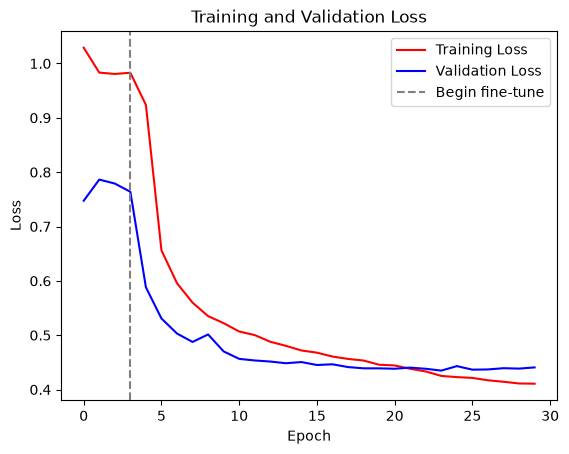

In [14]:
loss     = history1.history["loss"]     + history2.history["loss"]
val_loss = history1.history["val_loss"] + history2.history["val_loss"]

plt.plot(loss, color="red", label="Training Loss")
plt.plot(val_loss, color="blue", label="Validation Loss")
plt.axvline(len(history1.history["loss"]) - 1, ls="--", color="gray", label="Begin fine-tune")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend(); plt.show()

In [15]:
model.save("Model3.keras")

## 5. Danh gia tren tap test

In [16]:
test_set = image_dataset_from_directory(
    str(DATA_DIR / "test"),
    labels="inferred",
    label_mode="categorical",
    color_mode="rgb",
    batch_size=16,
    image_size=(128, 128),
    shuffle=False
)


Found 10848 files belonging to 4 classes.


In [17]:
test_loss,test_acc,f1_score = model.evaluate(test_set)

678/678 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9571 - f1_score: 0.9261 - loss: 0.4454


In [18]:
test_loss

0.44537416100502014

In [19]:
test_acc

0.9571349620819092

In [20]:
f1_score

0.9261064529418945

### 5.1 Model Evaluation

In [21]:
model = tf.keras.models.load_model("Model3.keras")


In [22]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 960)            │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         3,844 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,951,790 (34.15 MB)

 Trainable params: 2,975,796 (11.35 MB)

 Non-trainable params: 24,400 (95.31 KB)

 Optimizer params: 5,951,594 (22.70 MB)

In [23]:
test_set = image_dataset_from_directory(
    str(TEST_DIR),
    label_mode="categorical",
    batch_size=16,
    image_size=(128, 128),
    shuffle=False
)


Found 10848 files belonging to 4 classes.


In [24]:
##Computing True labels from test set
true_categories = tf.concat([y for x, y in test_set], axis=0)
Y_true = tf.argmax(true_categories, axis=1)

2026-10-16 00:52:46.242265: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [25]:
##Computing Predicted labels using test set
predicted_categories = model.predict(test_set)
Y_pred = tf.argmax(predicted_categories, axis=1)

678/678 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step


In [26]:
Y_true

<tf.Tensor: shape=(10848,), dtype=int64, numpy=array([0, 0, 0, ..., 3, 3, 3])>

In [27]:
Y_pred

<tf.Tensor: shape=(10848,), dtype=int64, numpy=array([0, 0, 0, ..., 3, 3, 3])>

### 5.2 Classification Report

In [29]:
cm = confusion_matrix(Y_true,Y_pred)
cm

array([[3542,   20,  110,    6],
       [  25, 1072,   16,   43],
       [  54,    6,  756,   63],
       [   7,   25,   90, 5013]])

              precision    recall  f1-score   support

         CNV     0.9763    0.9630    0.9696      3678
         DME     0.9546    0.9273    0.9408      1156
      DRUSEN     0.7778    0.8601    0.8169       879
      NORMAL     0.9781    0.9762    0.9772      5135

    accuracy                         0.9571     10848
   macro avg     0.9217    0.9317    0.9261     10848
weighted avg     0.9588    0.9571    0.9577     10848



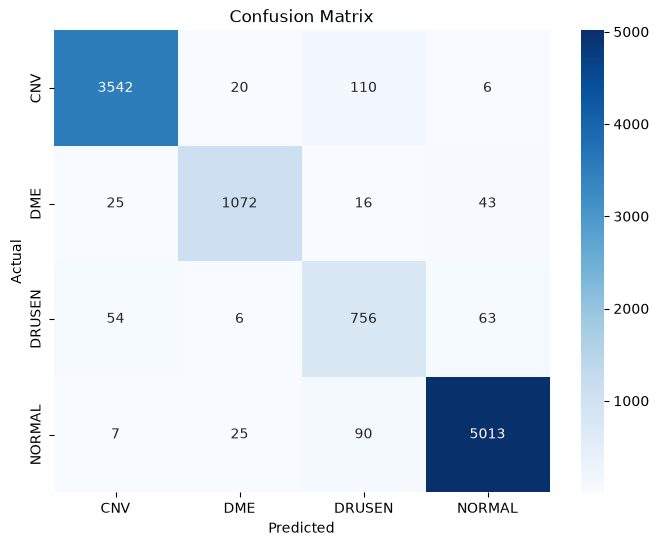

In [30]:

print(classification_report(Y_true, Y_pred, target_names=class_names, digits=4))

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### Confusion Matrix

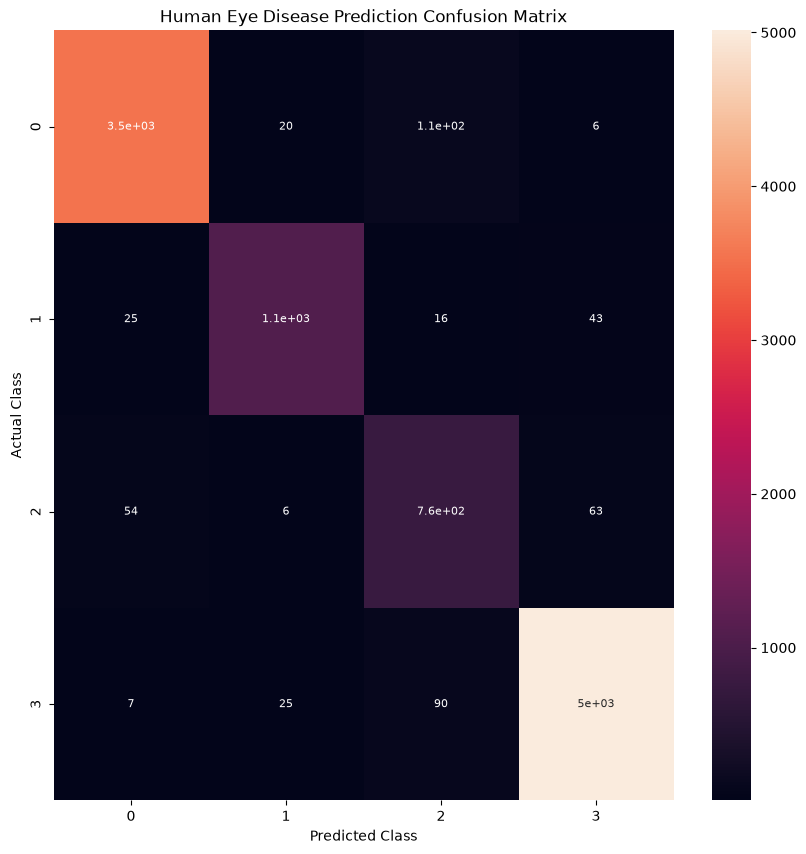

In [31]:
plt.figure(figsize=(10,10))
sns.heatmap(cm,annot=True,annot_kws={"size":8})
plt.xlabel("Predicted Class",fontsize=10)
plt.ylabel("Actual Class",fontsize=10)
plt.title("Human Eye Disease Prediction Confusion Matrix",fontsize=12)
plt.show()